# Prototype 4 — Interactive Bbox Editor

**Goal:** messy room photo → AI suggests bounding boxes → user edits (move, resize, delete, relabel) → confirmed boxes → per-item crops → categorize each crop → review grid.

**Flow:**
1. Load room photo
2. Detect items with Gemini 2.5 spatial → AI-suggested boxes
3. Interactive editor — edit boxes to your liking
4. ← **Stop here and edit.** Run the tagging cells only after you're happy with the boxes.
5. Crop confirmed boxes → remove background → categorize each crop
6. Review grid (mirrors `BulkAdd.tsx` step 2)

> **Quota note:** Cells marked `[API]` call Gemini. Steps 1–3 cost one detection call. Step 5 costs N categorize calls (one per confirmed box).

In [3]:
import os, sys, json
from pathlib import Path
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from PIL import Image
from IPython.display import display

load_dotenv(Path("..") / ".env")
sys.path.insert(0, str(Path("..")))

from lib.client import VISION_MODEL
from lib.images import resize_image, crop_bbox
from lib.detect_items import detect_items
from lib.categorize import categorize_item
from lib.remove_background import remove_background

print(f"VISION_MODEL:   {VISION_MODEL}")
print(f"API key set:    {bool(os.getenv("GEMINI_API_KEY"))}")
print(f"FAL key set:    {bool(os.getenv("FAL_KEY"))}")
Path("../outputs").mkdir(exist_ok=True)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


VISION_MODEL:   gemini-2.5-flash
API key set:    True
FAL key set:    True


## Step 1 — Load room photo

Default: the messy room photo from `inputs/`. Change `IMG_PATH` to any photo.

Loaded: pic.png
Original: 1684×2528  →  Resized: 799×1200


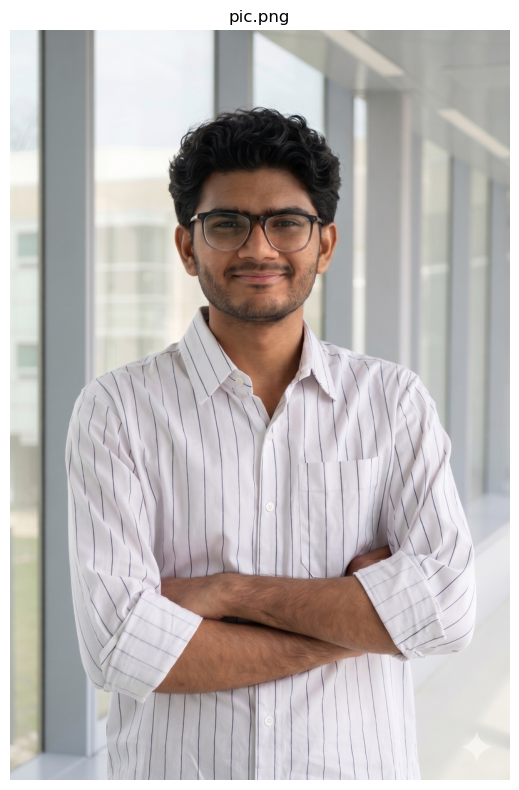

In [20]:
IMG_PATH = Path('../inputs/pic.png')  # ← swap to the other photo or any path

img_original = Image.open(IMG_PATH)
img = resize_image(img_original).convert('RGB')
img.save('../outputs/04_input.jpg', quality=90)  # save resized copy for the widget

print(f'Loaded: {IMG_PATH.name}')
print(f'Original: {img_original.width}×{img_original.height}  →  Resized: {img.width}×{img.height}')

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis('off')
plt.title(IMG_PATH.name)
plt.tight_layout()
plt.show()

## Step 2 — [API] Detect items with Gemini 2.5 spatial

Runs `detect_items()` which already applies NMS to remove duplicates.
Results are converted from Gemini's `[ymin, xmin, ymax, xmax]` normalized coords to pixel-space `{x, y, width, height}` for the widget.

In [23]:
print(f'Detecting items with {VISION_MODEL}...')
raw_detections = detect_items(img)
print(f'Found {len(raw_detections)} item(s) after NMS:')
for i, d in enumerate(raw_detections):
    print(f'  {i+1}. {d["label"]}  box_2d={d["box_2d"]}')


def gemini_box_to_widget(det: dict, img_w: int, img_h: int) -> dict:
    """Convert Gemini [ymin,xmin,ymax,xmax] normalized [0,1000] → widget {x,y,width,height} pixels."""
    ymin, xmin, ymax, xmax = det['box_2d']
    x = int(xmin / 1000 * img_w)
    y = int(ymin / 1000 * img_h)
    w = int((xmax - xmin) / 1000 * img_w)
    h = int((ymax - ymin) / 1000 * img_h)
    return {'x': x, 'y': y, 'width': w, 'height': h, 'label': det['label']}


def widget_box_to_gemini(box: dict, img_w: int, img_h: int) -> dict:
    """Convert widget {x,y,width,height} pixels → Gemini [ymin,xmin,ymax,xmax] normalized [0,1000]."""
    ymin = int(box['y'] / img_h * 1000)
    xmin = int(box['x'] / img_w * 1000)
    ymax = int((box['y'] + box['height']) / img_h * 1000)
    xmax = int((box['x'] + box['width']) / img_w * 1000)
    return {'box_2d': [ymin, xmin, ymax, xmax], 'label': box.get('label', 'item')}


W, H = img.width, img.height
ai_boxes = [gemini_box_to_widget(d, W, H) for d in raw_detections]

print(f'\nConverted to widget format ({W}×{H} pixel space):')
for b in ai_boxes:
    print(f'  {b["label"]}: x={b["x"]} y={b["y"]} w={b["width"]} h={b["height"]}')

Detecting items with gemini-2.5-flash...
Found 2 item(s) after NMS:
  1. white striped shirt  box_2d=[368, 114, 1000, 928]
  2. glasses  box_2d=[239, 360, 297, 622]

Converted to widget format (799×1200 pixel space):
  white striped shirt: x=91 y=441 w=650 h=758
  glasses: x=287 y=286 w=209 h=69


## Step 3 — Interactive bbox editor

The widget loads the room photo with AI-suggested boxes pre-filled.

**Controls:**
- **Drag box** — move it
- **Drag edge/corner handles** — resize
- **Click ✕** on a box — delete it
- **Draw new box** — click and drag on the image
- **Label dropdown** — change what item the box represents

When you're happy with the boxes, run **Step 4** to read the confirmed list.

In [25]:
from jupyter_bbox_widget import BBoxWidget

CLASSES = [
    'jacket', 'shirt', 'top', 'hoodie',
    'pants', 'jeans', 'shorts', 'skirt',
    'shoes', 'sneakers', 'boots',
    'bag', 'backpack',
    'accessory', 'other',
]

editor = BBoxWidget(
    image='../outputs/04_input.jpg',
    classes=CLASSES,
    bboxes=ai_boxes,
)

display(editor)

## Step 4 — Read confirmed boxes

Run this cell after you finish editing above. It reads `editor.bboxes`, converts back to Gemini's normalized format, and previews the confirmed boxes over the image.

> **Stop here** — review the preview. Only run Step 5 when the boxes look right.

In [ ]:
confirmed_widget = editor.bboxes
confirmed = [widget_box_to_gemini(b, W, H) for b in confirmed_widget]

print(f'Confirmed {len(confirmed)} item(s):')
for i, d in enumerate(confirmed):
    print(f'  {i+1}. "{d["label"]}"  box_2d={d["box_2d"]}')

# Preview confirmed boxes over the image
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.imshow(img)
colors = plt.cm.Set2.colors

for i, (det, box) in enumerate(zip(confirmed, confirmed_widget)):
    color = colors[i % len(colors)]
    rect = patches.Rectangle(
        (box['x'], box['y']), box['width'], box['height'],
        linewidth=2, edgecolor=color, facecolor='none'
    )
    ax.add_patch(rect)
    ax.text(
        box['x'], box['y'] - 5, det['label'],
        color=color, fontsize=9, fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.75, pad=2)
    )

ax.set_title(f'Confirmed boxes ({len(confirmed)} items) — check before tagging')
ax.axis('off')
plt.tight_layout()
plt.savefig('../outputs/04_confirmed_boxes.png', dpi=150)
plt.show()
print('Saved → outputs/04_confirmed_boxes.png')

## Step 5 — Crop + background removal

Crops each confirmed box from the image. Applies rembg if available.

In [ ]:
# ← Change provider here: "rembg" (local/free) or "fal" (BiRefNet, needs FAL_KEY)
BG_PROVIDER = "fal"

crops = [crop_bbox(img, d["box_2d"]) for d in confirmed]

print(f"Removing backgrounds ({BG_PROVIDER})...")
cutouts = []
for i, crop in enumerate(crops):
    print(f"  {i+1}/{len(crops)}: {confirmed[i]["label"]}...")
    cutouts.append(remove_background(crop, provider=BG_PROVIDER))

# Preview cutouts
n = len(cutouts)
cols = min(n, 4)
rows = max(1, (n + cols - 1) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 4))
axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, (cutout, det) in enumerate(zip(cutouts, confirmed)):
    bg = Image.new('RGBA', cutout.size if hasattr(cutout, 'size') else crops[i].size, (220, 220, 220, 255))
    if hasattr(cutout, 'mode') and cutout.mode == 'RGBA':
        bg.paste(cutout, mask=cutout.split()[3])
        display_img = bg
    else:
        display_img = cutout
    axes_flat[i].imshow(display_img)
    axes_flat[i].set_title(det['label'], fontsize=8)
    axes_flat[i].axis('off')
for j in range(n, len(axes_flat)):
    axes_flat[j].axis('off')

plt.suptitle('Cutouts — ready for tagging', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/04_cutouts.png', dpi=150)
plt.show()
print('Saved → outputs/04_cutouts.png')

## Step 6 — [API] Categorize each cutout

Runs `categorize_item()` on each confirmed crop. Uses the label from your edited box as a hint.

**Cost:** one Gemini call per item.

In [ ]:
print(f'Categorizing {len(cutouts)} item(s)...')
classifications = []
for i, (cutout, det) in enumerate(zip(cutouts, confirmed)):
    label = det['label']
    print(f'  {i+1}/{len(cutouts)}: {label}...')
    # Pass the user's label as an existing subcategory hint
    cl = categorize_item(cutout.convert('RGB') if hasattr(cutout, 'convert') else cutout,
                         existing_subcategories=[label])
    classifications.append(cl)
    print(f'    → {cl.get("category")} / {cl.get("subcategory")} ({cl.get("primary_color")})')

print('\nDone.')

## Step 7 — Review grid

Final output: each confirmed item as a data card — cutout photo + AI tags.
Mirrors the `BulkAdd.tsx` review grid the web app will show.

In [ ]:
n = len(classifications)
cols = min(n, 3)
rows = max(1, (n + cols - 1) // cols)
fig = plt.figure(figsize=(cols * 5, rows * 7))
gs = gridspec.GridSpec(rows, cols, figure=fig, hspace=0.5, wspace=0.3)

for i, (cutout, cl, det) in enumerate(zip(cutouts, classifications, confirmed)):
    row, col = divmod(i, cols)
    ax = fig.add_subplot(gs[row, col])

    bg = Image.new('RGBA', cutout.size if hasattr(cutout, 'size') else crops[i].size, (245, 245, 245, 255))
    if hasattr(cutout, 'mode') and cutout.mode == 'RGBA':
        bg.paste(cutout, mask=cutout.split()[3])
        display_img = bg
    else:
        display_img = cutout

    ax.imshow(display_img)
    tags = (
        f"{cl.get('category', '—')} / {cl.get('subcategory', '—')}\n"
        f"Color:    {cl.get('primary_color', '—')}\n"
        f"Material: {cl.get('material') or '—'}\n"
        f"Season:   {', '.join(cl.get('season', []))}\n"
        f"Tags:     {', '.join(cl.get('suggested_tags', []))}\n"
        f"\n{cl.get('ai_description', '')}"
    )
    ax.set_title(tags, fontsize=7, loc='left', wrap=True)
    ax.axis('off')

plt.suptitle(f'Review Grid — {n} confirmed items', fontsize=14, fontweight='bold')
plt.savefig('../outputs/04_review_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → outputs/04_review_grid.png')

print('\n--- Final classifications (ready to insertItem) ---')
for i, (cl, det) in enumerate(zip(classifications, confirmed)):
    print(f'\nItem {i+1}: {det["label"]}')
    print(json.dumps(cl, indent=2))